# CRISP-DM | Predicting international soccer results before kickoff

Estimate win, draw, and loss probabilities for men's national teams. A match preview writer can use the probabilities as a historical comparison.

[Dataset on Kaggle](https://www.kaggle.com/datasets/martj42/international-football-results-from-1872-to-2017)

Use a standard CPU runtime and run the cells in order.

Methodology reference: [IBM CRISP-DM](https://www.ibm.com/docs/en/spss-modeler/saas?topic=dm-crisp-help-overview). Kaggle snapshot version: 138.

## Methodology map

| CRISP-DM phase | Evidence |
| --- | --- |
| Business understanding | User decision, resources, constraints, success criteria, project plan |
| Data understanding | Source profile, quality audit, match coverage, training competition profile |
| Data preparation | Selection and cleaning, Elo construction, temporal partitions, Elo conservation audit |
| Modeling | Training design, baseline and candidates, temporal stability and validation trade-offs |
| Evaluation | Held-out metrics, uncertainty, draw reliability, segment errors, decision review |
| Deployment | Reproducible release, scoring contract, input checks, monitoring and refresh plan |

## Setup

Download the Kaggle archive, check the selected CSVs against their SHA-256 fingerprints, and report the package versions. The fingerprints protect the analysis against changes to the source files.

In [1]:
from pathlib import Path
from urllib.request import Request, urlopen
from zipfile import ZipFile
from io import BytesIO
import hashlib
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from importlib.metadata import version

KAGGLE_DATASET = 'martj42/international-football-results-from-1872-to-2017'
KAGGLE_VERSION = 138
EXPECTED_SHA256 = {'results.csv': 'b38434f8f74cd9faacb269eb1c97760fc2dfac43fcb211779e0bd2cbb48f89e3'}
ARTIFACTS = Path(os.environ.get("PROJECT_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(parents=True, exist_ok=True)


def load_kaggle_tables():
    archive_path = os.environ.get("PROJECT_DATA_ZIP")
    if archive_path:
        archive = Path(archive_path).read_bytes()
    else:
        url = f"https://www.kaggle.com/api/v1/datasets/download/{KAGGLE_DATASET}?datasetVersionNumber={KAGGLE_VERSION}"
        with urlopen(Request(url, headers={"User-Agent": "CMPE255-notebook/1.0"}), timeout=120) as response:
            archive = response.read()
    tables = {}
    with ZipFile(BytesIO(archive)) as zipped:
        for filename, expected in EXPECTED_SHA256.items():
            content = zipped.read(filename)
            actual = hashlib.sha256(content).hexdigest()
            if actual != expected:
                raise ValueError(f"{filename} changed. Use the archived Kaggle version described in the README.")
            tables[filename] = pd.read_csv(BytesIO(content), na_values=[r"\N"])
    return tables


def save_json(filename, payload):
    (ARTIFACTS / filename).write_text(json.dumps(payload, indent=2) + "\n")


tables = load_kaggle_tables()
print("Python", sys.version.split()[0])
print({name: version(name) for name in ("pandas", "numpy", "scikit-learn", "matplotlib")})
print({name: df.shape for name, df in tables.items()})
print("Kaggle snapshot:", KAGGLE_VERSION)

Python 3.14.7
{'pandas': '3.1.1', 'numpy': '2.5.4', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2'}
{'results.csv': (49945, 9)}
Kaggle snapshot: 138


## 1. Business understanding

The question is whether prior results and venue improve on the overall frequency of each outcome. We predict from the perspective of the listed home team. A neutral venue means that the home label marks the order of teams in the data.

Log loss penalizes confident errors in probabilities. Macro F1 gives each outcome the same weight when scoring hard predictions. Use log loss as the primary criterion and report macro F1 to reveal performance on draws.

### 1.1 Decision and success criteria

A writer uses the output to add context to a preview. The decision is whether to cite the probability distribution. Primary success means lower test log loss than the outcome-frequency baseline. Require a paired interval below zero before calling the gain consistent within the test sample. Inspect draw recall before using top labels. This dataset covers men's senior national-team results and does not include lineup or injury updates.

### 1.2 Resources, risks, and project plan

The inputs are a versioned match archive and a CPU runtime. First audit the source and set the date partitions. Then derive ratings, select a model on validation, and review the held-out outcomes. Release the model as a JSON file for the Colab demo. The main risks are temporal leakage, unequal coverage by team, and stale ratings. The date-level checks, segment tables, and visible snapshot date address those risks.

## 2. Data understanding

One row describes one international match. The scores define the target, and they exclude shootouts. The date, team names, and neutral venue flag inform the prediction. Tournament type supports exploration.

The venue chart describes 1990–2025, including later matches. It does not select the model or tune its settings. The draw rates were 23.4% at non-neutral venues and 23.6% at neutral venues.

In [2]:
matches = tables["results.csv"]
preview_columns = ["date", "home_team", "away_team", "home_score", "away_score", "neutral"]
display(matches[preview_columns].tail(5))
display(matches[preview_columns].isna().sum().rename("missing").to_frame())

,date,home_team,away_team,home_score,away_score,neutral
49940,2026-10-06,Belize,French Guiana,0,1,False
49941,2026-10-06,Turks and Caicos Islands,Montserrat,1,4,False
49942,2026-10-06,Antigua and Barbuda,Aruba,3,2,False
49943,2026-10-06,Saint Martin,Bahamas,6,0,True
49944,2026-10-06,Saudi Arabia,United Arab Emirates,2,0,False


,missing
date,0
home_team,0
away_team,0
home_score,0
away_score,0
neutral,0


outcome,Draw,Loss,Win
neutral,,,
False,0.234,0.258,0.507
True,0.236,0.337,0.427


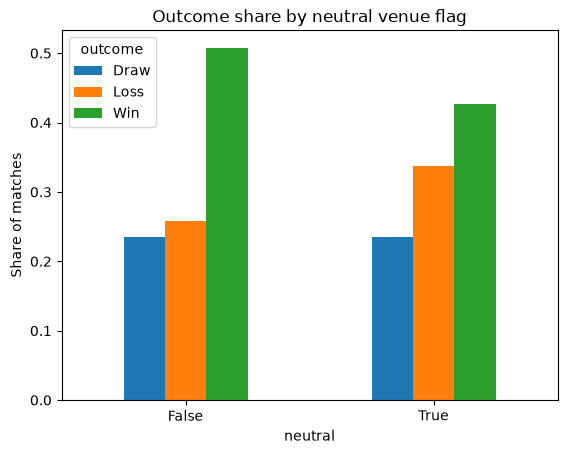

In [3]:
matches = matches.dropna(subset=preview_columns).drop_duplicates(subset=preview_columns).copy()
matches["date"] = pd.to_datetime(matches["date"])
matches = matches.loc[matches["date"].dt.year.between(1990, 2025)].sort_values("date")
matches["outcome"] = np.select(
    [matches.home_score.gt(matches.away_score), matches.home_score.lt(matches.away_score)],
    ["Win", "Loss"], default="Draw"
)
venue_mix = pd.crosstab(matches.neutral, matches.outcome, normalize="index")
display(venue_mix.round(3))
venue_mix.plot.bar(rot=0, title="Outcome share by neutral venue flag", ylabel="Share of matches")
plt.show()

### 2.1 Verify data quality

Count issues in the source before filtering. The six required fields are listed in the preview.

In [4]:
raw_matches = tables["results.csv"]
source_dates = pd.to_datetime(raw_matches.date, errors="coerce")
source_quality = pd.Series({
    "source_rows": len(raw_matches),
    "missing_required_values": raw_matches[preview_columns].isna().any(axis=1).sum(),
    "unparseable_dates": source_dates.isna().sum(),
    "duplicate_required_fields": raw_matches.duplicated(preview_columns).sum(),
    "negative_scores": raw_matches[["home_score", "away_score"]].lt(0).any(axis=1).sum(),
    "same_team_rows": raw_matches.home_team.eq(raw_matches.away_team).sum(),
    "outside_study_years": (~source_dates.dt.year.between(1990, 2025)).sum(),
    "retained_rows": len(matches),
})
display(source_quality.to_frame("rows"))
assert source_quality[["unparseable_dates", "negative_scores", "same_team_rows"]].eq(0).all()

,rows
source_rows,49945
missing_required_values,0
unparseable_dates,0
duplicate_required_fields,0
negative_scores,0
same_team_rows,0
outside_study_years,17925
retained_rows,32020


### 2.2 Describe training competitions and outcome mix

The training period supplies the exploratory comparison. Tournaments are context, rather than model inputs.

In [5]:
training_matches = matches.loc[matches.date.dt.year.between(2000, 2018)]
competition_profile = training_matches.groupby("tournament").agg(
    matches=("outcome", "size"),
    draw_rate=("outcome", lambda x: x.eq("Draw").mean()),
    neutral_rate=("neutral", "mean"),
).nlargest(8, "matches")
display(competition_profile.round(3))

,matches,draw_rate,neutral_rate
tournament,,,
Friendly,6515,0.272,0.192
FIFA World Cup qualification,4073,0.214,0.047
UEFA Euro qualification,1031,0.185,0.014
African Cup of Nations qualification,948,0.229,0.020
AFC Asian Cup qualification,425,0.174,0.200
CECAFA Cup,341,0.226,0.754
FIFA World Cup,320,0.228,0.897
African Cup of Nations,317,0.309,0.814


### 2.3 Examine match coverage by year

A coverage chart shows how many matches support the estimate in different periods. Lower coverage can change who appears in the data.

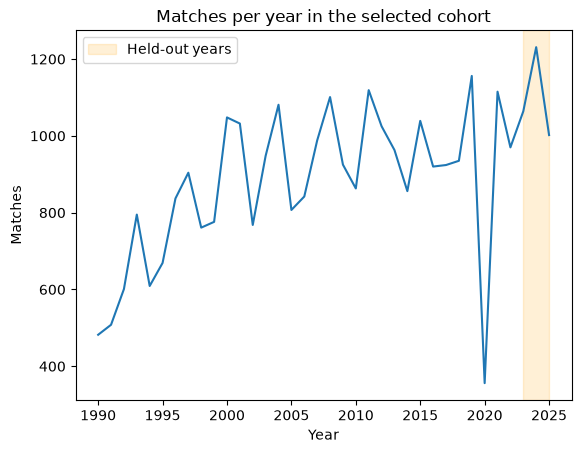

In [6]:
annual_coverage = matches.groupby(matches.date.dt.year).size()
ax = annual_coverage.plot(title="Matches per year in the selected cohort", ylabel="Matches", xlabel="Year")
ax.axvspan(2023, 2025, color="orange", alpha=.16, label="Held-out years")
ax.legend()
plt.show()

## 3. Data preparation

Elo is a rating that updates after each match. Both teams start at 1,500. The update gives a larger reward when a lower-rated team wins. We use 1990–1999 as a warm-up period and derive features from earlier dates only. Each match on the same date sees the ratings as they stood at the start of that date. Validation and test ratings can incorporate completed matches on earlier dates because those results were available at prediction time.

The rating update factor is fixed at 20 before any model fitting. Venue enters the outcome model. The Elo update uses team strength and the match result.

In [7]:
from collections import defaultdict

FEATURES = ["elo_difference", "neutral"]
ratings = defaultdict(lambda: 1500.0)
rows = []
for date, day in matches.groupby("date", sort=True):
    changes = defaultdict(float)
    for match in day.itertuples():
        difference = ratings[match.home_team] - ratings[match.away_team]
        expected = 1 / (1 + 10 ** (-difference / 400))
        actual = {"Win": 1.0, "Draw": 0.5, "Loss": 0.0}[match.outcome]
        rows.append((date, match.home_team, match.away_team, difference, int(match.neutral), match.outcome))
        adjustment = 20 * (actual - expected)
        changes[match.home_team] += adjustment
        changes[match.away_team] -= adjustment
    for team, change in changes.items():
        ratings[team] += change

features = pd.DataFrame(rows, columns=["date", "home", "away", *FEATURES, "outcome"])
display(features.tail(5))

,date,home,away,elo_difference,neutral,outcome
32015,2025-12-30,Botswana,DR Congo,-191.172233,1,Loss
32016,2025-12-31,Sudan,Burkina Faso,-162.732184,1,Loss
32017,2025-12-31,Gabon,Ivory Coast,-157.162599,1,Loss
32018,2025-12-31,Equatorial Guinea,Algeria,-307.833821,1,Loss
32019,2025-12-31,Mozambique,Cameroon,-149.667842,1,Loss


In [8]:
year = features.date.dt.year
train = features.loc[year.between(2000, 2018)]
validation = features.loc[year.between(2019, 2022)]
test = features.loc[year.between(2023, 2025)]
assert train.date.max() < validation.date.min() < validation.date.max() < test.date.min()
display(pd.Series({"train": len(train), "validation": len(validation), "test": len(test)}))

train         18184
validation     3597
test           3297
dtype: int64

Read the observed date coverage after filtering. Older matches help initialize ratings. They stay outside the modeling splits.

In [9]:
split_coverage = pd.DataFrame([
    (label, len(part), part.date.min().date(), part.date.max().date())
    for label, part in [("Train", train), ("Validation", validation), ("Test", test)]
], columns=["split", "matches", "first_match", "last_match"])
display(split_coverage)

,split,matches,first_match,last_match
0,Train,18184,2000-01-04,2018-12-31
1,Validation,3597,2019-01-02,2022-12-30
2,Test,3297,2023-01-02,2025-12-31


### 3.1 Reconcile the feature table and partitions

Compare selected source rows with prepared rows. Warm-up rows update ratings and stay outside fitting and evaluation.

In [10]:
warmup = features.loc[features.date.dt.year.lt(2000)]
assert len(features) == len(matches) == len(warmup) + len(train) + len(validation) + len(test)
assert features[FEATURES].notna().all().all()
assert features.neutral.isin([0, 1]).all()
parts = {"Warm-up": warmup, "Train": train, "Validation": validation, "Test": test}
display(pd.DataFrame({name: part.outcome.value_counts() for name, part in parts.items()}).T)

outcome,Win,Loss,Draw
Warm-up,3449,1807,1686
Train,8775,5140,4269
Validation,1748,1040,809
Test,1552,992,753


### 3.2 Inspect the prediction inputs

Report quantiles for Elo difference across periods. These summaries help diagnose drift and do not select the model.

In [11]:
elo_coverage = pd.DataFrame({
    name: part.elo_difference.quantile([.05, .50, .95])
    for name, part in parts.items()
}).T
elo_coverage.columns = ["5th percentile", "median", "95th percentile"]
display(elo_coverage.round(1))

,5th percentile,median,95th percentile
Warm-up,-145.7,0.8,152.6
Train,-239.7,12.2,253.3
Validation,-286.4,25.6,310.7
Test,-302.1,28.4,324.2


### 3.3 Manually verify a rating update

Recompute the rating changes for the busiest date from its stored pre-match features. Check that the full rating history conserves total rating points, since a gain for one team is a loss for the other.

In [12]:
audit_day = matches.groupby("date").size().idxmax()
audit_matches = matches.loc[matches.date.eq(audit_day)]
audit_features = features.loc[features.date.eq(audit_day)]
assert len(audit_matches) == len(audit_features)
audit_expected = 1 / (1 + 10 ** (-audit_features.elo_difference.to_numpy() / 400))
audit_actual = audit_features.outcome.map({"Win": 1, "Draw": .5, "Loss": 0}).to_numpy()
audit_delta = 20 * (audit_actual - audit_expected)
display(audit_features.assign(home_elo_change=audit_delta).head(5))
assert np.isclose(sum(ratings.values()), 1500 * len(ratings))
print("Rating mass is conserved after all updates.")

,date,home,away,elo_difference,neutral,outcome,home_elo_change
18543,2012-02-29,Montenegro,Iceland,114.782981,0,Win,6.811450
18544,2012-02-29,Tajikistan,North Korea,-97.428868,0,Draw,2.732964
18545,2012-02-29,Switzerland,Argentina,-139.232714,0,Loss,-6.194147
18546,2012-02-29,Spain,Venezuela,304.955908,0,Win,2.947179
18547,2012-02-29,South Africa,Senegal,34.056554,0,Draw,-0.977099


Rating mass is conserved after all updates.


## 4. Modeling

A baseline is a simple point of comparison. Here it predicts the same probabilities for every match from the training outcome frequencies. Multiclass logistic regression uses the Elo difference and venue flag to estimate three probabilities. We compare three regularization strengths on the validation period and then refit the chosen model with training and validation data.

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score, log_loss
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def soccer_model(strength):
    return make_pipeline(StandardScaler(), LogisticRegression(C=strength, max_iter=1000))


validation_scores = {}
for strength in (0.1, 1.0, 10.0):
    candidate = soccer_model(strength).fit(train[FEATURES], train.outcome)
    validation_scores[strength] = log_loss(validation.outcome, candidate.predict_proba(validation[FEATURES]), labels=candidate.classes_)
selected_strength = min(validation_scores, key=validation_scores.get)
development = pd.concat([train, validation])
model = soccer_model(selected_strength).fit(development[FEATURES], development.outcome)
baseline = DummyClassifier(strategy="prior").fit(development[FEATURES], development.outcome)
display(pd.Series(validation_scores, name="validation_log_loss"))
print("Selected C:", selected_strength)

0.1     0.865348
1.0     0.865301
10.0    0.865297
Name: validation_log_loss, dtype: float64

Selected C: 10.0


### 4.1 Inspect the validation comparison

Read the candidate scores and compare the selected validation score with the historical prior fitted on the training split.

In [14]:
training_prior = DummyClassifier(strategy="prior").fit(train[FEATURES], train.outcome)
validation_prior_loss = log_loss(
    validation.outcome, training_prior.predict_proba(validation[FEATURES]), labels=training_prior.classes_
)
display(pd.DataFrame({
    "candidate_C": list(validation_scores),
    "validation_log_loss": list(validation_scores.values()),
    "change_vs_training_prior": [loss - validation_prior_loss for loss in validation_scores.values()],
}).round(5))

,candidate_C,validation_log_loss,change_vs_training_prior
0,0.1,0.86535,-0.17998
1,1.0,0.86530,-0.18003
2,10.0,0.86530,-0.18003


### 4.2 Check stability within the validation period

Use models fitted only on 2000–2018 to see whether the validation gain is shared across years. The final test stays outside this check.

In [15]:
validation_model = soccer_model(selected_strength).fit(train[FEATURES], train.outcome)
validation_year_rows = []
for season, group in validation.groupby(validation.date.dt.year):
    validation_year_rows.append({
        "year": season, "matches": len(group),
        "model_log_loss": log_loss(group.outcome, validation_model.predict_proba(group[FEATURES]), labels=validation_model.classes_),
        "prior_log_loss": log_loss(group.outcome, training_prior.predict_proba(group[FEATURES]), labels=training_prior.classes_),
    })
display(pd.DataFrame(validation_year_rows).round(4))

,year,matches,model_log_loss,prior_log_loss
0,2019,1156,0.8419,1.0397
1,2020,356,0.9727,1.0817
2,2021,1115,0.8091,1.0448
3,2022,970,0.9184,1.0393


The selected model beat the frequency baseline in every validation year. The gap was smallest in 2020, when the sample was also smallest. The annual table does not tell us why the gap changed.

## 5. Evaluation

The test period estimates performance on future matches. Read log loss and macro F1 together. A draw can receive a useful probability even when it is rarely the most likely outcome. Review the confusion matrix to see which classes the model predicts.

Compare the paired change in loss across 1,000 resamples of match dates. Each sampled date retains all of its matches. This interval describes uncertainty within the test cohort and does not account for long-run shifts across eras.

In [16]:
scores = {}
for label, estimator in {"Training frequencies": baseline, "Elo and venue": model}.items():
    probabilities = estimator.predict_proba(test[FEATURES])
    predictions = estimator.predict(test[FEATURES])
    scores[label] = {
        "log_loss": log_loss(test.outcome, probabilities, labels=estimator.classes_),
        "macro_f1": f1_score(test.outcome, predictions, average="macro"),
    }
display(pd.DataFrame(scores).T.round(4))
matrix = confusion_matrix(test.outcome, model.predict(test[FEATURES]), labels=model.classes_)
display(pd.DataFrame(matrix, index=model.classes_, columns=model.classes_).rename_axis("Actual"))

from sklearn.metrics import classification_report

print(classification_report(test.outcome, model.predict(test[FEATURES]), zero_division=0))
true_class = pd.Categorical(test.outcome, categories=model.classes_).codes
row_index = np.arange(len(test))
model_p = model.predict_proba(test[FEATURES])[row_index, true_class]
prior_p = baseline.predict_proba(test[FEATURES])[row_index, true_class]
loss_difference = np.log(prior_p) - np.log(model_p)
dates = pd.DataFrame({"date": test.date.to_numpy(), "difference": loss_difference}).groupby("date").difference.agg(["sum", "size"])
rng = np.random.default_rng(255)
resampled_dates = rng.integers(0, len(dates), (1000, len(dates)))
bootstrap = dates["sum"].to_numpy()[resampled_dates].sum(axis=1) / dates["size"].to_numpy()[resampled_dates].sum(axis=1)
paired_interval = np.quantile(bootstrap, [.025, .975]).tolist()
print(f"Model minus prior log loss: {loss_difference.mean():.4f}, 95% date-block interval {paired_interval[0]:.4f} to {paired_interval[1]:.4f}")
save_json("evaluation.json", {"test_matches": len(test), "selected_C": selected_strength, "metrics": scores, "paired_date_bootstrap_95pct": paired_interval, "labels": model.classes_.tolist(), "confusion_matrix": matrix.tolist()})

,log_loss,macro_f1
Training frequencies,1.0540,0.2134
Elo and venue,0.8765,0.4423


,Draw,Loss,Win
Actual,,,
Draw,0,278,475
Loss,0,634,358
Win,0,199,1353


              precision    recall  f1-score   support

        Draw       0.00      0.00      0.00       753
        Loss       0.57      0.64      0.60       992
         Win       0.62      0.87      0.72      1552

    accuracy                           0.60      3297
   macro avg       0.40      0.50      0.44      3297
weighted avg       0.46      0.60      0.52      3297

Model minus prior log loss: -0.1775, 95% date-block interval -0.1975 to -0.1582


In [17]:
segment_rows = []
for venue, group in test.groupby("neutral"):
    p = model.predict_proba(group[FEATURES])
    segment_rows.append({
        "venue": "Neutral" if venue else "Non-neutral",
        "matches": len(group),
        "log_loss": log_loss(group.outcome, p, labels=model.classes_),
    })
display(pd.DataFrame(segment_rows).round(4))
draw_row = list(model.classes_).index("Draw")
print("True draws:", matrix[draw_row].sum(), "| correctly predicted draws:", matrix[draw_row, draw_row])

,venue,matches,log_loss
0,Non-neutral,2219,0.8528
1,Neutral,1078,0.9254


True draws: 753 | correctly predicted draws: 0


The model assigns probability to draws, but it never ranks a draw first on the test set. Treat it as a match preview aid. Assess it separately before using hard predictions or extending the analysis to other competitions.

An ablation isolates one input. Compare each input alone with the combined model. These diagnostics do not change the model selected on validation.

In [18]:
input_diagnostics = {}
for field in FEATURES:
    one_input = soccer_model(selected_strength).fit(development[[field]], development.outcome)
    input_diagnostics[field] = log_loss(test.outcome, one_input.predict_proba(test[[field]]), labels=one_input.classes_)
display(pd.Series(input_diagnostics, name="test_log_loss").round(4))
draw_index = list(model.classes_).index("Draw")
draw_probabilities = model.predict_proba(test[FEATURES])[:, draw_index]
draw_check = pd.DataFrame({"predicted": draw_probabilities, "actual": test.outcome.eq("Draw").to_numpy()})
bins = pd.cut(draw_check.predicted, [0, .15, .20, .25, .30, 1], include_lowest=True)
display(draw_check.groupby(bins, observed=True).agg(rows=("actual", "size"), predicted=("predicted", "mean"), observed=("actual", "mean")).round(4))

elo_difference    0.8777
neutral           1.0494
Name: test_log_loss, dtype: float64

,rows,predicted,observed
predicted,,,
"(-0.001, 0.15]",555,0.1051,0.0955
"(0.15, 0.2]",516,0.1758,0.2112
"(0.2, 0.25]",915,0.2279,0.2459
"(0.25, 0.3]",1311,0.2718,0.2792


### 5.1 Visualize the held-out confusion matrix

Normalize each row to compare recall across outcomes with different counts. The draw row shows the effect of using the highest probability as the label.

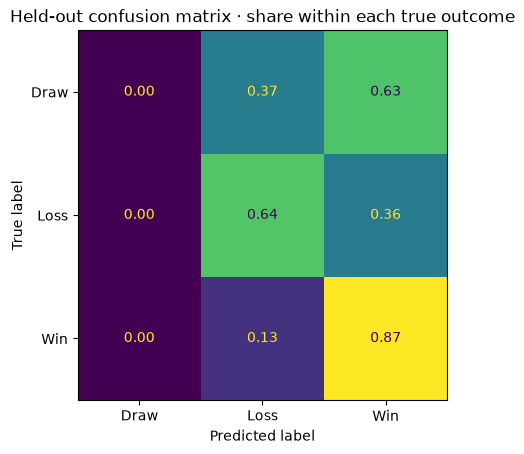

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay
normalized_matrix = matrix / matrix.sum(axis=1, keepdims=True)
ConfusionMatrixDisplay(normalized_matrix, display_labels=model.classes_).plot(values_format=".2f", colorbar=False)
plt.title("Held-out confusion matrix · share within each true outcome")
plt.show()

### 5.2 Inspect high-confidence errors

Review example misses to understand where a confident preview can still be wrong. The examples are diagnostic and do not change the selected model.

In [20]:
test_probability = model.predict_proba(test[FEATURES])
error_examples = test[["date", "home", "away", "outcome"]].assign(
    predicted=model.classes_[test_probability.argmax(axis=1)],
    confidence=test_probability.max(axis=1),
)
display(error_examples.loc[error_examples.predicted.ne(error_examples.outcome)].nlargest(8, "confidence").round(3))

/var/folders/xf/wwxdg7jn6j5gqbs9jbs_3q3h0000gn/T/ipykernel_95928/2540723619.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(error_examples.loc[error_examples.predicted.ne(error_examples.outcome)].nlargest(8, "confidence").round(3))


,date,home,away,outcome,predicted,confidence
30196,2024-06-07,Romania,Liechtenstein,Draw,Win,0.955
30880,2024-11-17,Thailand,Laos,Draw,Win,0.930
31883,2025-11-17,Bahrain,Somalia,Loss,Win,0.924
30809,2024-11-14,France,Israel,Draw,Win,0.918
29966,2024-03-21,South Africa,Andorra,Draw,Win,0.915
29269,2023-09-07,Austria,Moldova,Draw,Win,0.915
31951,2025-11-26,Oman,Somalia,Draw,Win,0.913
29489,2023-10-15,Poland,Moldova,Draw,Win,0.912


### 5.3 Review the success criteria

Use the paired interval and the draw result to decide whether to release the demo as a probability aid.

In [21]:
review = pd.Series({
    "better_log_loss_than_prior": loss_difference.mean() < 0,
    "paired_interval_below_zero": paired_interval[1] < 0,
    "retrieves_any_draw_as_top_label": matrix[draw_row, draw_row] > 0,
})
display(review.to_frame("passes"))

,passes
better_log_loss_than_prior,True
paired_interval_below_zero,True
retrieves_any_draw_as_top_label,False


The probability model meets both log-loss criteria. The top-label rule failed for draws. Use the probability distribution in previews and review draw performance before using a top-label decision.

## 6. Deployment

The prediction demo runs in Colab. The release artifact contains the fitted coefficients, scaling values, outcome labels, and team ratings. Inference reads only the artifact. It does not read match data or retrain the model.

In a fresh Colab session, run the cell labeled "This cell also works by itself in a new runtime." It downloads the saved artifact from the submission repository when a local copy is absent. The cell reports the date of the rating snapshot. Use the demo for matchups after that date. As more results arrive, rerun the notebook and compare performance on a new held-out period before replacing the artifact.

The cell downloads a commit-pinned file and checks its SHA-256 digest. Its output is for the first-listed team. Swapping teams can change probabilities beyond simply exchanging win and loss.

In [22]:
scaler, classifier = model.steps[0][1], model.steps[1][1]
save_json("prediction_model.json", {
    "classes": classifier.classes_.tolist(),
    "feature_order": FEATURES,
    "mean": scaler.mean_.tolist(),
    "scale": scaler.scale_.tolist(),
    "coefficients": classifier.coef_.tolist(),
    "intercepts": classifier.intercept_.tolist(),
    "ratings": dict(ratings),
    "rating_snapshot": str(matches.date.max().date()),
})

In [23]:
# This cell also works by itself in a new runtime.
import json
from pathlib import Path
import numpy as np

artifact_path = Path("artifacts/prediction_model.json")
if "ARTIFACTS" in globals():
    artifact_path = ARTIFACTS / "prediction_model.json"
if not artifact_path.exists():
    import hashlib
    from urllib.request import urlopen
    artifact_path.parent.mkdir(parents=True, exist_ok=True)
    model_url = "https://raw.githubusercontent.com/isaackimmi/cmpe255-data-mining-process/38ec26204dce614c2218e3ba6adffcd1db81cb71/crisp-dm-soccer/artifacts/prediction_model.json"
    with urlopen(model_url, timeout=30) as response:
        payload = response.read()
    if hashlib.sha256(payload).hexdigest() != "c7887db05687102132e7e1f4ebc9c3d3488d9ee9ae4cc52ddbd6fd50d2fac934":
        raise ValueError("The downloaded model does not match the release checksum.")
    artifact_path.write_bytes(payload)
release = json.loads(artifact_path.read_text())


def predict_match(home_team, away_team, neutral_venue):
    if home_team == away_team:
        raise ValueError("Choose two different teams.")
    available_ratings = release["ratings"]
    if home_team not in available_ratings or away_team not in available_ratings:
        raise ValueError("Choose teams that appear in the ratings snapshot.")
    inputs = np.array([available_ratings[home_team] - available_ratings[away_team], int(neutral_venue)])
    normalized = (inputs - release["mean"]) / release["scale"]
    logits = np.asarray(release["coefficients"]) @ normalized + release["intercepts"]
    weights = np.exp(logits - logits.max())
    return dict(zip(release["classes"], weights / weights.sum()))


home_team = "Argentina"  # @param {type:"string"}
away_team = "France"  # @param {type:"string"}
neutral_venue = True  # @param {type:"boolean"}
demo = predict_match(home_team, away_team, neutral_venue)
print("Ratings through", release["rating_snapshot"])
print({label: f"{value:.1%}" for label, value in demo.items()})

Ratings through 2025-12-31
{'Draw': '25.4%', 'Loss': '26.3%', 'Win': '48.4%'}


In [24]:
for first, second, is_neutral in [("Argentina", "France", True), ("Japan", "South Korea", False), ("France", "Argentina", False)]:
    example = pd.DataFrame([[ratings[first] - ratings[second], int(is_neutral)]], columns=FEATURES)
    exported = list(predict_match(first, second, is_neutral).values())
    np.testing.assert_allclose(exported, model.predict_proba(example)[0])
    assert np.isclose(sum(exported), 1)
print("The exported model matches the training pipeline for three demo matchups.")

The exported model matches the training pipeline for three demo matchups.


The deployment phase ends with a reproducible Colab inference demo and the GitHub release artifact. The artifact keeps a frozen rating snapshot, so it cannot reflect newer matches unless we rebuild it.

### 6.1 Check the scoring inputs and release behavior

Verify the demo rejects identical teams and unknown names. Run the scoring cell alone in a new runtime to load the archived model.

In [25]:
for home_name, away_name in [("France", "France"), ("Unknown team", "France")]:
    try:
        predict_match(home_name, away_name, True)
    except ValueError as error:
        print(f"{home_name} vs {away_name}: {error}")
    else:
        raise AssertionError("Invalid matchup was accepted")
display(pd.DataFrame([
    {"fixture": "Argentina vs France · neutral", **predict_match("Argentina", "France", True)},
    {"fixture": "Argentina vs France · home", **predict_match("Argentina", "France", False)},
]).round(4))

France vs France: Choose two different teams.
Unknown team vs France: Choose teams that appear in the ratings snapshot.


,fixture,Draw,Loss,Win
0,Argentina vs France · neutral,0.2536,0.2627,0.4836
1,Argentina vs France · home,0.2476,0.1616,0.5908


### 6.2 Monitor and refresh

Use the date printed by the demo to decide whether the ratings are fresh enough. At the next refresh, rebuild from a new verified snapshot and compare the new model with the prior on dates after the current cutoff. Review log loss by venue, draw recall, and unknown teams before replacing the release. Keep the previous artifact available so an older preview can still be reproduced.